# DDS-8555 Assignment 8, Notebook 3 of 3: San Francisco Crime Classification
**Nathan Weber** · National University · DDS-8555: Predictive Analysis · Dr. Alexander Watt

**How to run:** Runtime → Run all (about 30 to 45 minutes on a free Colab runtime; keep the tab open). Approve the Google Drive prompt. When the upload button appears, choose the Kaggle `sf-crime.zip` (only the first time; the zips inside it are unpacked automatically). The three Kaggle submission files are zipped, download automatically, and are also saved to Drive → DDS8555 → output.

| Requirement | Where |
|---|---|
| Tree-based model 1: random forest | Part 3 |
| Tree-based model 2: gradient boosting (with a regularization check) | Part 4 |
| Support vector machine (linear, with calibrated probabilities) | Part 5 |
| Kaggle submissions (multi-class log loss) | Part 6 |
| Interpretation and assumption checks | Parts 6 and 7 |

In [1]:
# ==============================================================================
# DDS-8555 Predictive Analysis | Assignment 8 (Notebook 3 of 3): Build & Evaluate Classification Models: SF Crime
# National University | Instructor: Dr. Alexander V. Watt | Author: Nathan Weber
# Notebook: DDS8555_ASGN8Part3of3_SFCrime_NWeber.ipynb
# Paper:    WeberN_DDS8555-910002634_ASGN8Part1of1.docx  (the written report; code is not reproduced there)
# Version:  v1.1, 2026-11-02 (see the change log at the end of this cell)
# ------------------------------------------------------------------------------
# RUN:      Google Colab -> Runtime -> Run all (also runs locally with Python 3.10+).
#           Needs: numpy, pandas, matplotlib, scikit-learn, scipy.
# INPUTS:   Kaggle 'San Francisco Crime Classification' (sf-crime): sf-crime.zip, or train.csv,
#           test.csv, sampleSubmission.csv (zipped or not) in Google Drive/MyDrive/DDS8555/sfcrime.
#           https://www.kaggle.com/competitions/sf-crime (SFPD incident reports, 2003-01 to 2015-05)
# OUTPUTS:  Drive/MyDrive/DDS8555/output: A8_crime_model1_rf.zip, A8_crime_model2_boosting.zip, A8_crime_model3_svm.zip, A8_crime_fig_classes.png, A8_crime_fig_tuning.png, A8_crime_fig_calibration.png, A8_crime_fig_importance.png, A8_crime_results.json
# ------------------------------------------------------------------------------
# QUESTION: Predict the probability of each of 39 crime categories from time and place for 884,262 test incidents, comparing a random forest, gradient boosting, and a linear support vector machine.
# TARGET:   Category (39 classes). Kaggle metric = multi-class log loss, so every model outputs
#           calibrated probabilities, floored at 0.0001 and renormalized.
# CLEANING: Descript and Resolution exist only in train (they describe the outcome) and are dropped;
#           67 train and 76 test rows with latitude 90 get their police district's median location.
# VALIDATION:Week-grouped holdout: 20% of training weeks (GroupShuffleSplit, random_state=42), because
#           Kaggle's test set is made of whole alternate weeks. Tuning and model choice use this holdout.
# SEEDS:    random_state=42 for the split, the forest, boosting, the SVM subsamples, and the bootstrap.
# DEPENDS ON: None. Independent of the other two A8 notebooks.
# CHECKS:   input SHA-256 fingerprints, row counts, column names, and package versions
#           are printed below and at the end, so a re-run can be compared line by line.
# ------------------------------------------------------------------------------
# CHANGE LOG:
#   v1.0  2026-10-28  First version.
#   v1.1  2026-11-02  Added standard errors for every holdout log loss (row-level and a
#                     week-block bootstrap, because rows within a week are not independent),
#                     paired standard errors for the forest leaf-size rule and for the
#                     model-vs-model gaps; data-provenance note; Part 6 label corrected
#                     (the submitted models are the holdout-scored ones; no refit).
# ==============================================================================

In [2]:
## ---- 0. Setup and imports ------------------------------------------------------
# ---- 0. Setup: runs in Google Colab (also runs locally) ----
import sys, os, glob, zipfile, json, time, warnings, hashlib, datetime
warnings.filterwarnings("ignore"); os.environ["PYTHONWARNINGS"] = "ignore"
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive, files
    drive.mount("/content/drive")
    BASE = "/content/drive/MyDrive/DDS8555"
    !pip -q install --no-deps ISLP
else:
    BASE = os.environ.get("DDS8555_BASE", ".")
DATA_DIR = os.path.join(BASE, "sfcrime")
OUT_DIR = os.path.join(BASE, "output")
os.makedirs(DATA_DIR, exist_ok=True); os.makedirs(OUT_DIR, exist_ok=True)

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
pd.set_option("display.width", 120); pd.set_option("display.max_columns", 30)
plt.rcParams["figure.dpi"] = 110
RESULTS = {}          # every number the paper uses is stored here and printed at the end
T0 = time.time()

def unzip_all(folder):
    """Extract every zip in the folder (and zips inside zips), once."""
    for _ in range(2):
        for z in glob.glob(os.path.join(folder, "*.zip")):
            with zipfile.ZipFile(z) as f:
                for name in f.namelist():
                    target = os.path.join(folder, os.path.basename(name))
                    if name.endswith("/") or os.path.exists(target):
                        continue
                    with f.open(name) as src, open(target, "wb") as dst:
                        dst.write(src.read())

def get_files(need):
    """Make sure every file in `need` is in DATA_DIR; in Colab, ask for an upload once if not."""
    unzip_all(DATA_DIR)
    if IN_COLAB and not all(os.path.exists(os.path.join(DATA_DIR, f)) for f in need):
        print("Choose the Kaggle download (the zip, or the CSV files):")
        for name, data in files.upload().items():
            open(os.path.join(DATA_DIR, name), "wb").write(data)
        unzip_all(DATA_DIR)
    missing = [f for f in need if not os.path.exists(os.path.join(DATA_DIR, f))]
    assert not missing, f"Missing files in {DATA_DIR}: {missing}  (found: {sorted(os.listdir(DATA_DIR))})"

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

def fingerprint(names):
    fp = {f: sha256(os.path.join(DATA_DIR, f)) for f in names}
    print("Run started (UTC):", datetime.datetime.now(datetime.timezone.utc).strftime("%Y-%m-%d %H:%M"))
    for f, h in fp.items():
        print(f"SHA-256 {f:<28} {h}")
    return fp

def save_fig(name):
    plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, name), dpi=150); plt.show()

def download(path):
    if IN_COLAB:
        files.download(path)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Part 1. Load, check, and fingerprint the data
Two training columns, `Descript` and `Resolution`, are not in the test file because they record what the incident turned out to be. Using them would leak the answer, so they are dropped. **Where the data come from:** San Francisco Police Department incident reports, January 2003 to May 2015, as released for the Kaggle competition. These are *reported* incidents, not all crime, in one city and period, so the results describe what police recorded there and then, and may not carry over to other cities, later years, or unreported crime. A small number of incidents have a placeholder location (latitude 90, in the Arctic); these are moved to the median location of their police district. The categories are very unbalanced, which matters for log loss: a model is punished heavily when it is confident and wrong, including on rare classes.

Choose the Kaggle download (the zip, or the CSV files):


Saving sf-crime.zip to sf-crime.zip
train: (878049, 9)  test: (884262, 7)
Run started (UTC): 2026-11-10 00:09
SHA-256 train.csv                    a72eb782299af2b68f9fade22bc3235a023b5ec7e0d1e540824718bb8af84402
SHA-256 test.csv                     f5abddb5f1fcda6f1c5c81b2423b163022da1ddf0e60385170f827978eb9b8de
SHA-256 sampleSubmission.csv         3f268be0fe8782bc3fd5a39a1ea464ab1e4cac9a6257e883a66f65502b9a522c
dates: 2003-01-06 00:01:00 to 2015-05-13 23:53:00; categories: 39; districts: 10
largest classes: {'LARCENY/THEFT': 0.199, 'OTHER OFFENSES': 0.144, 'NON-CRIMINAL': 0.105, 'ASSAULT': 0.088, 'DRUG/NARCOTIC': 0.061}
smallest classes: {'SEX OFFENSES NON FORCIBLE': 148, 'GAMBLING': 146, 'PORNOGRAPHY/OBSCENE MAT': 22, 'TREA': 6}
exact duplicate rows: 2323; rows sharing time and address with another row: 37.3%; latitude-90 rows: train 67, test 76
dropped (outcome-only, not in test): ['Descript', 'Resolution']


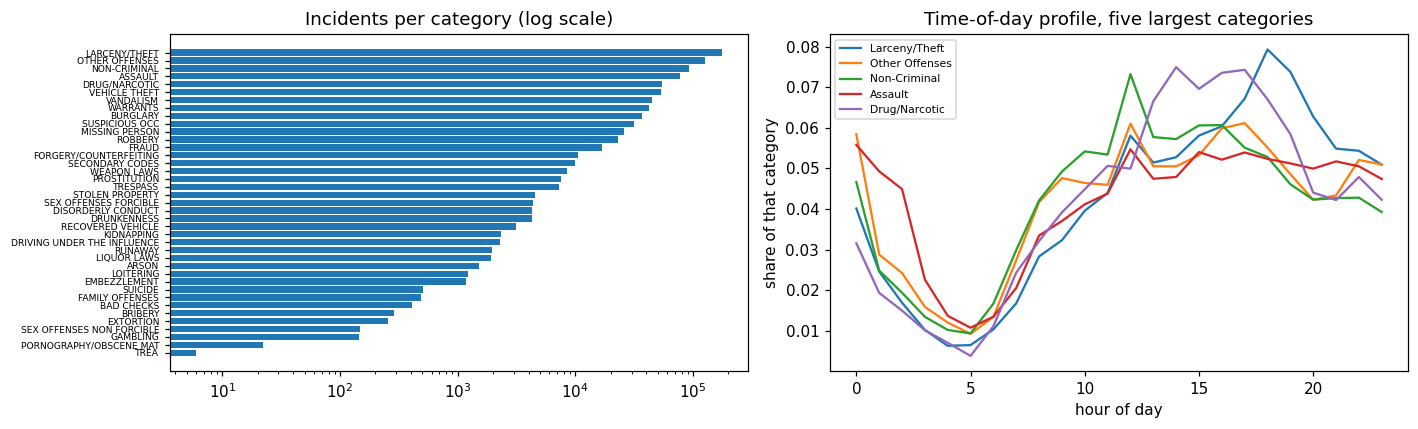

In [3]:
## ---- 1. Load, check, fingerprint -----------------------------------------------
NEED = ["train.csv", "test.csv", "sampleSubmission.csv"]
get_files(NEED)
train = pd.read_csv(os.path.join(DATA_DIR, "train.csv")); test = pd.read_csv(os.path.join(DATA_DIR, "test.csv"))
sample_cols = pd.read_csv(os.path.join(DATA_DIR, "sampleSubmission.csv"), nrows=2).columns.tolist()
print("train:", train.shape, " test:", test.shape)
assert {"Dates", "Category", "PdDistrict", "Address", "X", "Y"} <= set(train.columns) and "Id" in test
FP = fingerprint(NEED)
CL = sample_cols[1:]                                   # the 39 categories in Kaggle's column order
assert sorted(CL) == sorted(train.Category.unique()), "category list differs from the sample submission"
counts = train.Category.value_counts()
dup = int(train.duplicated().sum())
multi = train.duplicated(subset=["Dates", "Address"], keep=False).mean()
bad_tr, bad_te = int((train.Y > 40).sum()), int((test.Y > 40).sum())
print(f"dates: {train.Dates.min()} to {train.Dates.max()}; categories: {len(CL)}; districts: {train.PdDistrict.nunique()}")
print("largest classes:", (counts.head(5) / len(train)).round(3).to_dict())
print("smallest classes:", counts.tail(4).to_dict())
print(f"exact duplicate rows: {dup}; rows sharing time and address with another row: {multi:.1%}; latitude-90 rows: train {bad_tr}, test {bad_te}")
print("dropped (outcome-only, not in test):", [c for c in train.columns if c not in test.columns and c != "Category"])
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].barh(counts.index[::-1], counts.values[::-1]); ax[0].set_xscale("log"); ax[0].tick_params(axis="y", labelsize=6)
ax[0].set_title("Incidents per category (log scale)")
hr = pd.to_datetime(train.Dates).dt.hour
for c in counts.index[:5]:
    ax[1].plot(hr[train.Category == c].value_counts(normalize=True).sort_index(), label=c.title())
ax[1].set_xlabel("hour of day"); ax[1].set_ylabel("share of that category"); ax[1].legend(fontsize=7); ax[1].set_title("Time-of-day profile, five largest categories")
save_fig("A8_crime_fig_classes.png")
RESULTS["data"] = {"n_train": len(train), "n_test": len(test), "n_classes": len(CL), "sha256": FP, "start": train.Dates.min(), "end": train.Dates.max(),
                   "top5_share": (counts.head(5) / len(train)).round(4).to_dict(), "smallest": counts.tail(4).to_dict(),
                   "duplicates": dup, "multi_row_share": float(multi), "bad_coords_train": bad_tr, "bad_coords_test": bad_te}

## Part 2. Features and the validation design
Only time and place are available, so the features describe those carefully:
* **Time:** year, month, day, hour, minute, and day of week. Reports logged at exactly :00 or :30 are flagged, because rounded times often mean an officer estimated the time, which is more common for some categories.
* **Place:** longitude and latitude, the same point in rotated coordinates (30°, 45°, 60°) so tree splits can follow diagonal street grids, distance from the city centre, police district, whether the address is a block or an intersection, the street type (ST, AV, ...), and how often the address appears (log count).

**Validation.** Kaggle built its test set from alternate whole weeks. Rows from the same week, and often the same incident, are alike, so a random-row split would overstate accuracy. The holdout is therefore 20% of training *weeks*. The baseline is a model that ignores the features and predicts each category's overall frequency.

**How precise is a holdout score?** Log loss is an average over about 178,000 rows, so each score gets a standard error two ways: the naive one (row SD / √n, which assumes independent rows) and a **week-block bootstrap** (resample the holdout weeks 1,000 times), which respects the fact that rows in the same week are alike. Differences between two models are judged on the *paired* per-row difference, which is much more precise than comparing two separate scores. A tie rule such as "within 0.005" is meaningful only if 0.005 is about two of those standard errors or more.

In [4]:
## ---- 2. Features, week-grouped holdout, baseline -------------------------------
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import log_loss, accuracy_score
med = train[train.Y < 40].groupby("PdDistrict")[["X", "Y"]].median()
addr_n = pd.concat([train.Address, test.Address]).value_counts()
SUFFIX = r"\b(ST|AV|BL|WY|DR|RD|LN|PL|CT|TR|HY|CR|WAY|PZ|AL|EX|TER)\b"
DISTRICTS = sorted(train.PdDistrict.unique())
def features(d):
    t = pd.to_datetime(d.Dates)
    o = pd.DataFrame({"year": t.dt.year, "month": t.dt.month, "day": t.dt.day, "hour": t.dt.hour, "minute": t.dt.minute, "dow": t.dt.dayofweek})
    o["min_0"] = (o.minute == 0).astype(int); o["min_30"] = (o.minute == 30).astype(int)
    bad = d.Y > 40
    X = d.X.where(~bad, d.PdDistrict.map(med.X)); Y = d.Y.where(~bad, d.PdDistrict.map(med.Y))
    o["X"], o["Y"] = X.values, Y.values
    for a in (30, 45, 60):
        r = np.deg2rad(a); o[f"rot{a}_x"] = X * np.cos(r) + Y * np.sin(r); o[f"rot{a}_y"] = Y * np.cos(r) - X * np.sin(r)
    o["dist_centre"] = np.hypot(X + 122.4194, Y - 37.7749)
    o["district"] = pd.Categorical(d.PdDistrict, categories=DISTRICTS).codes
    o["block"] = d.Address.str.contains("Block").astype(int); o["intersection"] = d.Address.str.contains("/").astype(int)
    o["street_type"] = d.Address.str.extract(SUFFIX, expand=False).fillna("OTHER")
    o["addr_log_count"] = np.log1p(d.Address.map(addr_n).values)
    return o
t0 = time.time()
F, F_test = features(train), features(test)
STYPES = sorted(F.street_type.unique())
for g in (F, F_test):
    g["street_code"] = pd.Categorical(g.street_type, categories=STYPES).codes
TREE_COLS = [c for c in F.columns if c != "street_type"]
y = pd.Categorical(train.Category, categories=CL).codes
week = ((pd.to_datetime(train.Dates) - pd.Timestamp("2003-01-01")).dt.days // 7).values
i_tr, i_ho = next(GroupShuffleSplit(n_splits=1, test_size=.2, random_state=42).split(F, y, week))
K = len(CL)
def full_proba(p, classes):
    """Spread a model's probabilities over all 39 columns, floor at 1e-4, renormalize (Kaggle clips 0 to 1e-15, which is costly)."""
    P = np.full((len(p), K), 1e-4); P[:, classes] = np.maximum(p, 1e-4)
    return P / P.sum(1, keepdims=True)
def score(P, idx):
    return {"log_loss": float(log_loss(y[idx], P, labels=range(K))), "accuracy": float(accuracy_score(y[idx], P.argmax(1)))}
prior = np.bincount(y[i_tr], minlength=K) / len(i_tr)
base = score(full_proba(np.tile(prior, (len(i_ho), 1)), np.arange(K)), i_ho)
# ---- standard errors for holdout log loss ----
WK_CODE = np.unique(week[i_ho], return_inverse=True)[1]          # holdout week of each holdout row
N_WK = np.bincount(WK_CODE)
BOOT = np.random.default_rng(42).integers(0, len(N_WK), (1000, len(N_WK)))   # 1,000 week-block resamples, reused for every comparison
def row_loss(P, idx):
    """Per-row log loss: minus the log of the probability given to the true category."""
    return -np.log(P[np.arange(len(idx)), y[idx]])
def uncert(l):
    """Mean of per-row losses (or paired differences) with a naive and a week-block bootstrap standard error."""
    s_wk = np.bincount(WK_CODE, weights=l)
    boot = s_wk[BOOT].sum(1) / N_WK[BOOT].sum(1)
    return {"mean": float(l.mean()), "se_rows": float(l.std(ddof=1) / np.sqrt(len(l))), "se_weeks": float(boot.std(ddof=1))}
LOSS = {"Baseline: category frequencies": row_loss(full_proba(np.tile(prior, (len(i_ho), 1)), np.arange(K)), i_ho)}
print(f"features: {len(TREE_COLS)} columns ({time.time() - t0:.0f} s); street types: {STYPES}")
print(f"holdout: {len(i_ho):,} rows from {len(np.unique(week[i_ho]))} of {len(np.unique(week))} weeks; training part: {len(i_tr):,} rows")
_u = uncert(LOSS["Baseline: category frequencies"])
print(f"baseline (category frequencies): log loss {base['log_loss']:.4f}, accuracy {base['accuracy']:.4f}; "
      f"SE {_u['se_rows']:.4f} (rows) / {_u['se_weeks']:.4f} (week blocks)")
MODELS = {"Baseline: category frequencies": dict(base, seconds=0.0)}
RESULTS["design"] = {"n_features": len(TREE_COLS), "features": TREE_COLS, "n_holdout": len(i_ho), "n_fit": len(i_tr),
                     "weeks_holdout": int(len(np.unique(week[i_ho]))), "weeks_total": int(len(np.unique(week))), "baseline": base}

features: 22 columns (8 s); street types: ['AL', 'AV', 'BL', 'CR', 'CT', 'DR', 'EX', 'HY', 'LN', 'OTHER', 'PL', 'PZ', 'RD', 'ST', 'TER', 'TR', 'WAY', 'WY']
holdout: 178,299 rows from 129 of 644 weeks; training part: 699,750 rows
baseline (category frequencies): log loss 2.6723, accuracy 0.2036; SE 0.0024 (rows) / 0.0075 (week blocks)


## Part 3. Model 1: random forest
A random forest grows many trees on bootstrap samples and lets each split consider only part of the features, so the trees disagree and their average is stable (ISLP Section 8.2.2). For log loss the probabilities matter, not just the vote. Very deep trees give near-0 or near-1 leaf frequencies that are punished heavily when wrong, so the **minimum leaf size** is tuned on the holdout. Each tree sees a 30% bootstrap sample and half of the features at each split, which keeps training time and memory manageable on 700,000 rows. Rule: the largest leaf size (the simplest forest) within 0.005 of the best holdout log loss.

In [5]:
## ---- 3. Model 1: random forest (leaf size tuned) -------------------------------
from sklearn.ensemble import RandomForestClassifier
RF_KW = dict(max_features=.5, max_samples=.3, n_jobs=-1, random_state=42)
rf_curve, rf_fits, rf_loss = {}, {}, {}
for leaf in (10, 20, 50):
    t = time.time()
    m = RandomForestClassifier(n_estimators=60, min_samples_leaf=leaf, **RF_KW).fit(F.iloc[i_tr][TREE_COLS], y[i_tr])
    _P = full_proba(m.predict_proba(F.iloc[i_ho][TREE_COLS]), m.classes_)
    rf_curve[leaf] = dict(score(_P, i_ho), seconds=time.time() - t)
    rf_loss[leaf] = row_loss(_P, i_ho); del _P
    rf_fits[leaf] = m
    print(f"min_samples_leaf {leaf:>3}: holdout log loss {rf_curve[leaf]['log_loss']:.4f}, accuracy {rf_curve[leaf]['accuracy']:.4f} ({rf_curve[leaf]['seconds']:.0f} s)")
best_ll = min(v["log_loss"] for v in rf_curve.values())
RF_LEAF = max(k for k, v in rf_curve.items() if v["log_loss"] <= best_ll + .005)
MODELS["Model 1: random forest"] = rf_curve[RF_LEAF]
print(f"chosen leaf size: {RF_LEAF}")
leaf_best = min(rf_curve, key=lambda k: rf_curve[k]["log_loss"])
rf_leaf_diff = {k: uncert(rf_loss[k] - rf_loss[leaf_best]) for k in rf_curve if k != leaf_best}
for k, u in rf_leaf_diff.items():
    print(f"  leaf {k} minus best leaf {leaf_best}: {u['mean']:+.4f} (paired SE {u['se_rows']:.4f} rows / {u['se_weeks']:.4f} week blocks)")
LOSS["Model 1: random forest"] = rf_loss[RF_LEAF]; del rf_loss
rf_ho = rf_fits[RF_LEAF]; del rf_fits, m                 # keep only the chosen forest (used again in the checks)
RESULTS["rf"] = {"curve": rf_curve, "leaf": RF_LEAF, "n_estimators": 60, "max_features": .5, "max_samples": .3,
                 "leaf_best": leaf_best, "leaf_diff_vs_best": rf_leaf_diff}

min_samples_leaf  10: holdout log loss 2.2838, accuracy 0.3164 (154 s)
min_samples_leaf  20: holdout log loss 2.2755, accuracy 0.3148 (123 s)
min_samples_leaf  50: holdout log loss 2.2828, accuracy 0.3106 (110 s)
chosen leaf size: 20
  leaf 10 minus best leaf 20: +0.0084 (paired SE 0.0008 rows / 0.0008 week blocks)
  leaf 50 minus best leaf 20: +0.0074 (paired SE 0.0006 rows / 0.0006 week blocks)


## Part 4. Model 2: gradient boosting (histogram-based), and why it needs regularization
Boosting adds small trees one at a time, each fitted to the errors left by the trees before it (ISLP Section 8.2.3). With 39 classes it grows 39 trees per round. The first check runs 30 rounds with and without regularization on the same 150,000-row sample. Unregularized leaves can be tiny, so rare classes get extreme scores, and log loss can end up *worse* than the baseline. The final model uses leaves of at least 200 incidents, an L2 penalty on leaf values, a shrinkage (learning rate) of 0.1, and early stopping when a 10% validation slice stops improving.

In [6]:
## ---- 4. Model 2: gradient boosting (regularization check, early stopping) ------
from sklearn.ensemble import HistGradientBoostingClassifier
def strat_sample(idx, n, floor=30, seed=42):
    """Stratified sample of about n rows from idx, keeping at least `floor` rows of every class (all of them if fewer)."""
    rng = np.random.default_rng(seed); frac = n / len(idx); out = []
    for c in range(K):
        pool = idx[y[idx] == c]
        if len(pool):
            out.append(rng.choice(pool, max(int(round(frac * len(pool))), min(len(pool), floor)), replace=False))
    return np.sort(np.concatenate(out))
s150 = strat_sample(i_tr, 150000)
reg_check = {}
for name, kw in (("unregularized", dict(min_samples_leaf=20, l2_regularization=0.0, max_bins=255)),
                 ("regularized", dict(min_samples_leaf=200, l2_regularization=1.0, max_bins=63))):
    m = HistGradientBoostingClassifier(learning_rate=.1, max_iter=30, max_leaf_nodes=31, early_stopping=False, random_state=42, **kw)
    m.fit(F.iloc[s150][TREE_COLS], y[s150])
    reg_check[name] = score(full_proba(m.predict_proba(F.iloc[i_ho][TREE_COLS]), m.classes_), i_ho)
    print(f"30 rounds, {name:<13}: holdout log loss {reg_check[name]['log_loss']:.4f} (baseline {base['log_loss']:.4f})")
HGB_KW = dict(learning_rate=.1, max_leaf_nodes=31, min_samples_leaf=200, l2_regularization=1.0, max_bins=63, random_state=42)
t = time.time()
hgb = HistGradientBoostingClassifier(max_iter=400, early_stopping=True, validation_fraction=.1, n_iter_no_change=10, **HGB_KW)
hgb.fit(F.iloc[i_tr][TREE_COLS], y[i_tr])
HGB_ITER = int(hgb.n_iter_)
MODELS["Model 2: gradient boosting"] = dict(score(full_proba(hgb.predict_proba(F.iloc[i_ho][TREE_COLS]), hgb.classes_), i_ho), seconds=time.time() - t)
print(f"early stopping kept {HGB_ITER} rounds; holdout log loss {MODELS['Model 2: gradient boosting']['log_loss']:.4f}, "
      f"accuracy {MODELS['Model 2: gradient boosting']['accuracy']:.4f} ({time.time() - t:.0f} s)")
RESULTS["hgb"] = {"reg_check": reg_check, "n_iter": HGB_ITER, "params": {k: v for k, v in HGB_KW.items() if k != "random_state"},
                  "val_loss_curve": [float(v) for v in -hgb.validation_score_]}

30 rounds, unregularized: holdout log loss 3.0366 (baseline 2.6723)
30 rounds, regularized  : holdout log loss 2.3043 (baseline 2.6723)
early stopping kept 400 rounds; holdout log loss 2.2361, accuracy 0.3241 (1968 s)


## Part 5. Model 3: support vector machine
A kernel SVM needs a similarity value for every pair of training rows (ISLP Section 9.3). For 878,049 rows that is about 7.7 × 10¹¹ pairs, which is far beyond Colab's memory. So a **linear** SVM is used. To let it follow non-linear patterns, the inputs are expanded into 0/1 indicators: hour, day of week, month, year, district, the :00/:30 flags, block or intersection, street type, and a 40 × 40 grid cell for location. An SVM gives margins, not probabilities, so `CalibratedClassifierCV` fits a sigmoid to the margins of each class on held-out folds (Platt scaling). The cost C, which sets how much margin violation is allowed, is tuned on a 60,000-row stratified sample. The final model uses 250,000 rows.

SVM inputs: 1106 indicator columns
C = 0.0003: holdout log loss 2.5133
C = 0.001: holdout log loss 2.4967
C = 0.003: holdout log loss 2.4912
C = 0.01 : holdout log loss 2.4961
C = 0.03 : holdout log loss 2.5095
chosen C = 0.003; 250,000-row model: holdout log loss 2.4846, accuracy 0.2672 (307 s)


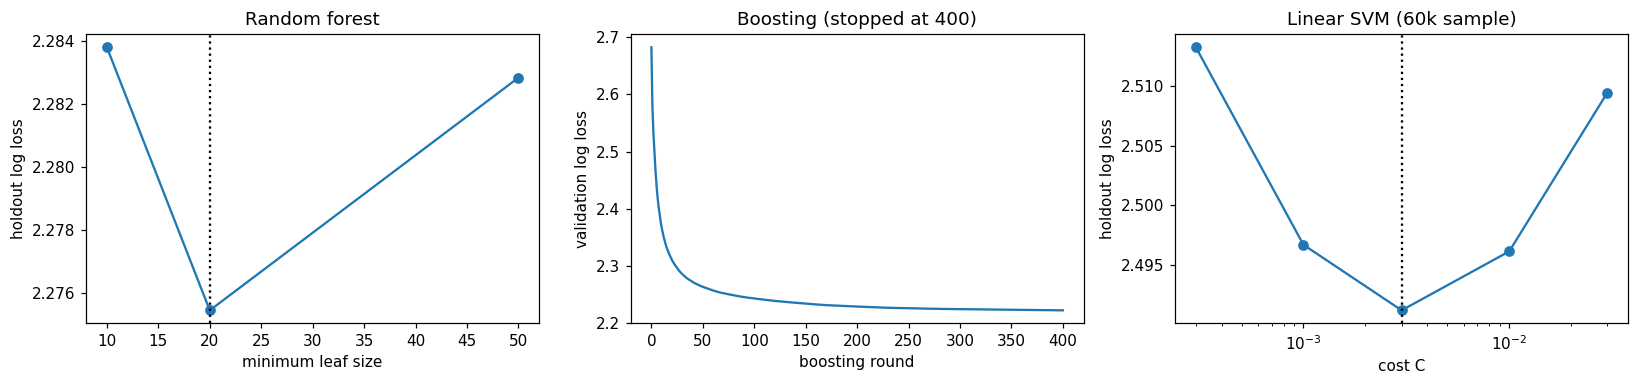

In [7]:
## ---- 5. Model 3: linear SVM with calibrated probabilities ----------------------
from sklearn.preprocessing import OneHotEncoder
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
edges_x = np.linspace(F.X.min(), F.X.max(), 41); edges_y = np.linspace(F.Y.min(), F.Y.max(), 41)
def svm_frame(g):
    h = g[["hour", "dow", "month", "year", "district", "min_0", "min_30", "block", "intersection", "street_type"]].copy()
    h["cell"] = np.clip(np.digitize(g.X, edges_x) - 1, 0, 39) * 40 + np.clip(np.digitize(g.Y, edges_y) - 1, 0, 39)
    return h.astype(str)
S, S_test = svm_frame(F), svm_frame(F_test)
enc = OneHotEncoder(handle_unknown="ignore", min_frequency=20).fit(S.iloc[i_tr])
Z, Z_test = enc.transform(S).tocsr(), enc.transform(S_test).tocsr()
print(f"SVM inputs: {Z.shape[1]} indicator columns")
s60 = strat_sample(i_tr, 60000)
svm_curve = {}
for C in (.0003, .001, .003, .01, .03):
    m = CalibratedClassifierCV(LinearSVC(C=C), method="sigmoid", cv=3).fit(Z[s60], y[s60])
    svm_curve[C] = score(full_proba(m.predict_proba(Z[i_ho]), m.classes_), i_ho)
    print(f"C = {C:<5}: holdout log loss {svm_curve[C]['log_loss']:.4f}")
SVM_C = min(svm_curve, key=lambda c: svm_curve[c]["log_loss"])
s250 = strat_sample(i_tr, 250000)
t = time.time()
svm = CalibratedClassifierCV(LinearSVC(C=SVM_C), method="sigmoid", cv=3).fit(Z[s250], y[s250])
MODELS["Model 3: linear SVM"] = dict(score(full_proba(svm.predict_proba(Z[i_ho]), svm.classes_), i_ho), seconds=time.time() - t)
print(f"chosen C = {SVM_C}; 250,000-row model: holdout log loss {MODELS['Model 3: linear SVM']['log_loss']:.4f}, "
      f"accuracy {MODELS['Model 3: linear SVM']['accuracy']:.4f} ({time.time() - t:.0f} s)")
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].plot(list(rf_curve), [v["log_loss"] for v in rf_curve.values()], "o-"); ax[0].axvline(RF_LEAF, ls=":", c="k")
ax[0].set_xlabel("minimum leaf size"); ax[0].set_ylabel("holdout log loss"); ax[0].set_title("Random forest")
ax[1].plot(RESULTS["hgb"]["val_loss_curve"]); ax[1].set_xlabel("boosting round"); ax[1].set_ylabel("validation log loss"); ax[1].set_title(f"Boosting (stopped at {HGB_ITER})")
ax[2].semilogx(list(svm_curve), [v["log_loss"] for v in svm_curve.values()], "o-"); ax[2].axvline(SVM_C, ls=":", c="k")
ax[2].set_xlabel("cost C"); ax[2].set_ylabel("holdout log loss"); ax[2].set_title("Linear SVM (60k sample)")
save_fig("A8_crime_fig_tuning.png")
RESULTS["svm"] = {"curve": svm_curve, "C": SVM_C, "n_columns": int(Z.shape[1]), "n_tune": len(s60), "n_final": len(s250)}

## Part 6. Compare and write the Kaggle files
Each submitted model is exactly the model scored on the holdout weeks, fitted on the other 80% of weeks. Refitting on every row would add some data, but refitting the boosting model alone takes about 20 minutes. Keeping the scored models also means the Kaggle score is an independent second check of the holdout estimate. Test probabilities are written in Kaggle's column order. The files are zipped because each is about 250 MB as plain CSV; Kaggle accepts zipped submissions.

In [8]:
## ---- 6. Compare models and write Kaggle files (no refit: submitted = holdout-scored) ---
table = pd.DataFrame(MODELS).T[["log_loss", "accuracy", "seconds"]].sort_values("log_loss")
print(table.round(4))
best = table.index[0]
def write_sub(P, name):
    df = pd.DataFrame(P, columns=CL); df.insert(0, "Id", test.Id.values)
    path = os.path.join(OUT_DIR, name + ".zip")
    df.to_csv(path, index=False, float_format="%.5f", compression={"method": "zip", "archive_name": name + ".csv"})
    print(f"saved {path} ({os.path.getsize(path) / 1e6:.0f} MB), {df.shape}"); download(path)
t = time.time()
write_sub(full_proba(rf_ho.predict_proba(F_test[TREE_COLS]), rf_ho.classes_), "A8_crime_model1_rf")
write_sub(full_proba(hgb.predict_proba(F_test[TREE_COLS]), hgb.classes_), "A8_crime_model2_boosting")
write_sub(full_proba(svm.predict_proba(Z_test), svm.classes_), "A8_crime_model3_svm")
rf_imp = pd.Series(rf_ho.feature_importances_, index=TREE_COLS).sort_values(ascending=False)
print(f"three files written ({time.time() - t:.0f} s)")
RESULTS["models"] = table.round(5).to_dict(orient="index"); RESULTS["best"] = best
RESULTS["rf_impurity_top"] = rf_imp.head(8).round(4).to_dict()

                                log_loss  accuracy    seconds
Model 2: gradient boosting        2.2361    0.3241  1968.3875
Model 1: random forest            2.2755    0.3148   123.2421
Model 3: linear SVM               2.4846    0.2672   306.5652
Baseline: category frequencies    2.6723    0.2036     0.0000
saved /content/drive/MyDrive/DDS8555/output/A8_crime_model1_rf.zip (57 MB), (884262, 40)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

saved /content/drive/MyDrive/DDS8555/output/A8_crime_model2_boosting.zip (57 MB), (884262, 40)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

saved /content/drive/MyDrive/DDS8555/output/A8_crime_model3_svm.zip (64 MB), (884262, 40)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

three files written (1285 s)


## Part 7. Checks
These models make no normality or constant-variance assumptions, so the checks target what they do rely on:
1. **Calibration.** Log loss rewards honest probabilities. Holdout incidents are grouped by the model's top probability, and the average predicted probability is compared with how often the top guess was right. The expected calibration error (ECE) is the average gap.
2. **Overfitting.** Log loss on a sample of the rows each model was fitted on, compared with the holdout.
3. **Independent rows.** Many incidents share a time and address with another row, so rows are not independent. The week-grouped holdout keeps such groups together.
4. **What drives the predictions.** Permutation importance on 10,000 holdout rows (the rise in log loss when a feature is shuffled), next to the forest's impurity importance.
5. **Class balance.** Recall by category for the best model: rare categories are almost never the top guess.
6. **Precision of the scores.** Standard errors for each model's holdout log loss and for the gaps between models (row-level and week-block bootstrap; see Part 2).

Model 1: random forest: expected calibration error 0.0092
Model 2: gradient boosting: expected calibration error 0.0045
Model 3: linear SVM: expected calibration error 0.0580


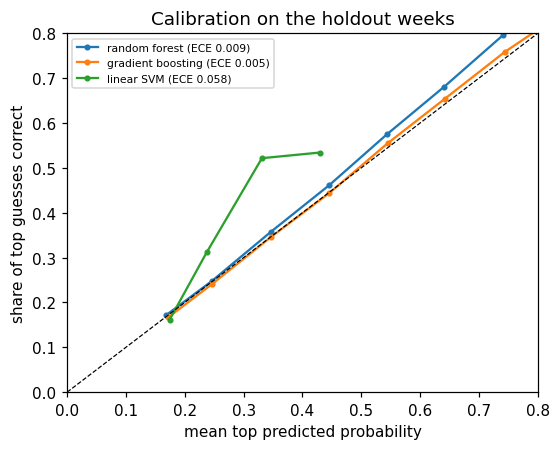

Model 1: random forest: log loss on fitted rows 2.0350 vs holdout 2.2755 (gap +0.2404)
Model 2: gradient boosting: log loss on fitted rows 1.9715 vs holdout 2.2361 (gap +0.2646)
Model 3: linear SVM: log loss on fitted rows 2.4786 vs holdout 2.4846 (gap +0.0060)
rows sharing time and address with another row: 37.3%; exact duplicates: 2323
permutation importance (boosting, rise in log loss): {'dist_centre': 0.2933, 'X': 0.276, 'rot60_y': 0.26, 'Y': 0.2555, 'rot60_x': 0.2457, 'addr_log_count': 0.2045, 'minute': 0.1828, 'block': 0.1127}
impurity importance (forest): {'addr_log_count': 0.1009, 'hour': 0.0786, 'minute': 0.0681, 'year': 0.0624, 'rot60_x': 0.0606, 'Y': 0.0563, 'rot30_y': 0.0547, 'dist_centre': 0.0538}


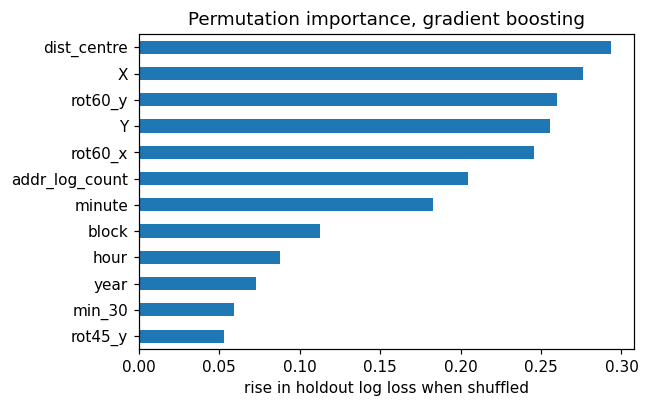

Model 2: gradient boosting: categories never chosen as the top guess on the holdout: 4 of 39
recall, five largest categories: {'LARCENY/THEFT': 0.735, 'OTHER OFFENSES': 0.439, 'NON-CRIMINAL': 0.198, 'ASSAULT': 0.21, 'DRUG/NARCOTIC': 0.45}
Baseline: category frequencies: holdout log loss 2.6723, SE 0.0024 (rows) / 0.0075 (week blocks)
Model 1: random forest: holdout log loss 2.2755, SE 0.0030 (rows) / 0.0048 (week blocks)
Model 2: gradient boosting: holdout log loss 2.2361, SE 0.0031 (rows) / 0.0053 (week blocks)
Model 3: linear SVM: holdout log loss 2.4846, SE 0.0025 (rows) / 0.0053 (week blocks)
Model 2: gradient boosting minus Model 1: random forest: -0.0394 (paired SE 0.0011 rows / 0.0012 week blocks)
Model 1: random forest minus Model 3: linear SVM: -0.2091 (paired SE 0.0016 rows / 0.0031 week blocks)
Model 2: gradient boosting minus Baseline: category frequencies: -0.4362 (paired SE 0.0023 rows / 0.0060 week blocks)


In [9]:
## ---- 7. Checks: calibration, overfitting, independence, importance, class balance, score precision ---
from sklearn.inspection import permutation_importance
P_ho = {"Model 1: random forest": None, "Model 2: gradient boosting": full_proba(hgb.predict_proba(F.iloc[i_ho][TREE_COLS]), hgb.classes_),
        "Model 3: linear SVM": full_proba(svm.predict_proba(Z[i_ho]), svm.classes_)}
P_ho["Model 1: random forest"] = full_proba(rf_ho.predict_proba(F.iloc[i_ho][TREE_COLS]), rf_ho.classes_)
# 1. calibration
def calib(P, idx, bins=10):
    conf = P.max(1); hit = (P.argmax(1) == y[idx]).astype(float)
    q = np.minimum((conf * bins).astype(int), bins - 1)
    rows = [(conf[q == b].mean(), hit[q == b].mean(), int((q == b).sum())) for b in range(bins) if (q == b).sum() > 0]
    ece = sum(n * abs(c - h) for c, h, n in rows) / len(idx)
    return rows, float(ece)
cal = {k: calib(P, i_ho) for k, P in P_ho.items()}
for k, (rows, ece) in cal.items():
    print(f"{k}: expected calibration error {ece:.4f}")
fig, ax = plt.subplots(figsize=(5.2, 4.2))
for k, (rows, ece) in cal.items():
    ax.plot([r[0] for r in rows], [r[1] for r in rows], "o-", ms=3, label=f"{k.split(': ')[1]} (ECE {ece:.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=.8); ax.set_xlim(0, .8); ax.set_ylim(0, .8)
ax.set_xlabel("mean top predicted probability"); ax.set_ylabel("share of top guesses correct"); ax.legend(fontsize=7); ax.set_title("Calibration on the holdout weeks")
save_fig("A8_crime_fig_calibration.png")
# 2. overfitting
s_fit = strat_sample(i_tr, 100000, seed=7)
over = {"Model 1: random forest": score(full_proba(rf_ho.predict_proba(F.iloc[s_fit][TREE_COLS]), rf_ho.classes_), s_fit),
        "Model 2: gradient boosting": score(full_proba(hgb.predict_proba(F.iloc[s_fit][TREE_COLS]), hgb.classes_), s_fit)}
s_svm_fit = s250[np.random.default_rng(7).choice(len(s250), 100000, replace=False)]
over["Model 3: linear SVM"] = score(full_proba(svm.predict_proba(Z[s_svm_fit]), svm.classes_), s_svm_fit)
for k in over:
    print(f"{k}: log loss on fitted rows {over[k]['log_loss']:.4f} vs holdout {MODELS[k]['log_loss']:.4f} (gap {MODELS[k]['log_loss'] - over[k]['log_loss']:+.4f})")
# 3. independence
print(f"rows sharing time and address with another row: {RESULTS['data']['multi_row_share']:.1%}; exact duplicates: {RESULTS['data']['duplicates']}")
# 4. importance
s_pi = np.random.default_rng(3).choice(i_ho, 10000, replace=False)
neg_ll = lambda est, Xs, ys: -log_loss(ys, full_proba(est.predict_proba(Xs), est.classes_), labels=range(K))   # all 39 labels, even if a sample lacks some
pi = permutation_importance(hgb, F.iloc[s_pi][TREE_COLS], y[s_pi], scoring=neg_ll, n_repeats=2, random_state=42, n_jobs=1)
perm = pd.Series(pi.importances_mean, index=TREE_COLS).sort_values(ascending=False)
print("permutation importance (boosting, rise in log loss):", perm.head(8).round(4).to_dict())
print("impurity importance (forest):", RESULTS["rf_impurity_top"])
fig, ax = plt.subplots(figsize=(6, 3.8))
perm.head(12)[::-1].plot.barh(ax=ax); ax.set_xlabel("rise in holdout log loss when shuffled"); ax.set_title("Permutation importance, gradient boosting")
save_fig("A8_crime_fig_importance.png")
# 5. per-class recall for the best model
Pb = P_ho[best]; pred = Pb.argmax(1)
recall = pd.Series({CL[c]: float((pred[y[i_ho] == c] == c).mean()) if (y[i_ho] == c).any() else np.nan for c in range(K)})
never = int((pd.Series(pred).value_counts().reindex(range(K)).fillna(0) == 0).sum())
print(f"{best}: categories never chosen as the top guess on the holdout: {never} of {K}")
print("recall, five largest categories:", recall[counts.index[:5]].round(3).to_dict())
# 6. precision of the holdout scores and of the gaps between models
LOSS["Model 2: gradient boosting"] = row_loss(P_ho["Model 2: gradient boosting"], i_ho)
LOSS["Model 3: linear SVM"] = row_loss(P_ho["Model 3: linear SVM"], i_ho)
unc_models = {k: uncert(v) for k, v in LOSS.items()}
for k, u in unc_models.items():
    print(f"{k}: holdout log loss {u['mean']:.4f}, SE {u['se_rows']:.4f} (rows) / {u['se_weeks']:.4f} (week blocks)")
PAIRS = [("Model 2: gradient boosting", "Model 1: random forest"), ("Model 1: random forest", "Model 3: linear SVM"),
         ("Model 2: gradient boosting", "Baseline: category frequencies")]
unc_pairs = {f"{a} minus {b}": uncert(LOSS[a] - LOSS[b]) for a, b in PAIRS}
for k, u in unc_pairs.items():
    print(f"{k}: {u['mean']:+.4f} (paired SE {u['se_rows']:.4f} rows / {u['se_weeks']:.4f} week blocks)")
RESULTS["checks"] = {"ece": {k: v[1] for k, v in cal.items()}, "calib_rows": {k: v[0] for k, v in cal.items()},
                     "score_se": unc_models, "pair_se": unc_pairs,
                     "overfit": {k: {"fit": over[k]["log_loss"], "holdout": MODELS[k]["log_loss"]} for k in over},
                     "perm_top": perm.head(8).round(5).to_dict(), "never_top": never, "recall_top5": recall[counts.index[:5]].round(4).to_dict()}

In [10]:
## ---- 8. Plain-language reading -------------------------------------------------
# ---- Plain-language reading (generated from the numbers above) ----
M_ = RESULTS["models"]; B_ = RESULTS["design"]["baseline"]; Ck = RESULTS["checks"]; H_ = RESULTS["hgb"]
print("* Holdout log loss (lower is better): " + "; ".join(f"{k} {v['log_loss']:.4f}" for k, v in M_.items()) + ".")
gain = B_["log_loss"] - M_[best]["log_loss"]
print(f"* Best: {best}. It lowers log loss by {gain:.3f} from the frequency baseline ({gain / B_['log_loss']:.0%}); "
      f"its top guess is right {M_[best]['accuracy']:.1%} of the time vs {B_['accuracy']:.1%} for always guessing the largest category.")
_pg = RESULTS["checks"]["pair_se"]["Model 2: gradient boosting minus Model 1: random forest"]
print(f"* Boosting minus forest: {_pg['mean']:+.4f} log loss, week-block SE {_pg['se_weeks']:.4f} "
      f"({abs(_pg['mean']) / _pg['se_weeks']:.0f} standard errors), so the ranking is {'not ' if abs(_pg['mean']) < 2 * _pg['se_weeks'] else ''}beyond holdout noise.")
_ld = RESULTS["rf"]["leaf_diff_vs_best"]
print("* Forest leaf-size rule (within 0.005): " + "; ".join(f"leaf {k} is {u['mean']:+.4f} vs the best (week-block SE {u['se_weeks']:.4f})" for k, u in _ld.items()) + ".")
print(f"* Regularization matters for boosting: after 30 rounds, unregularized {H_['reg_check']['unregularized']['log_loss']:.4f} vs "
      f"regularized {H_['reg_check']['regularized']['log_loss']:.4f} (baseline {B_['log_loss']:.4f}).")
print("* Calibration error (ECE): " + "; ".join(f"{k.split(': ')[1]} {v:.3f}" for k, v in Ck["ece"].items()) + ".")
print(f"* Strongest predictors (boosting, permutation): {list(Ck['perm_top'])[:4]}.")
_r = Ck["recall_top5"]
print(f"* Class balance: {Ck['never_top']} of {K} categories are never the top guess on the holdout. Among the five largest, recall runs from "
      f"{min(_r.values()):.0%} ({min(_r, key=_r.get).title()}) to {max(_r.values()):.0%} ({max(_r, key=_r.get).title()}), so the top guess is often wrong. "
      f"That is why log loss, which scores the whole probability spread, is the competition metric.")

* Holdout log loss (lower is better): Model 2: gradient boosting 2.2361; Model 1: random forest 2.2755; Model 3: linear SVM 2.4846; Baseline: category frequencies 2.6723.
* Best: Model 2: gradient boosting. It lowers log loss by 0.436 from the frequency baseline (16%); its top guess is right 32.4% of the time vs 20.4% for always guessing the largest category.
* Boosting minus forest: -0.0394 log loss, week-block SE 0.0012 (34 standard errors), so the ranking is beyond holdout noise.
* Forest leaf-size rule (within 0.005): leaf 10 is +0.0084 vs the best (week-block SE 0.0008); leaf 50 is +0.0074 vs the best (week-block SE 0.0006).
* Regularization matters for boosting: after 30 rounds, unregularized 3.0366 vs regularized 2.3043 (baseline 2.6723).
* Calibration error (ECE): random forest 0.009; gradient boosting 0.005; linear SVM 0.058.
* Strongest predictors (boosting, permutation): ['dist_centre', 'X', 'rot60_y', 'Y'].
* Class balance: 4 of 39 categories are never the top guess on the 

In [11]:
## ---- 9. Environment report and results JSON ------------------------------------
RESULTS_FILE = "A8_crime_results.json"
# ---- Environment report (the Python equivalent of R's sessionInfo()) ----
import importlib, platform
VERSIONS = {"python": platform.python_version()}
for pkg in ("numpy", "pandas", "sklearn", "statsmodels", "scipy", "matplotlib", "ISLP"):
    try:
        VERSIONS[pkg] = importlib.import_module(pkg).__version__
    except Exception:
        VERSIONS[pkg] = "not installed"
print("Environment:", VERSIONS)
print(f"Total run time: {(time.time() - T0) / 60:.1f} min")
RESULTS["environment"] = VERSIONS

# ---- Results used in the paper (printed so they are saved in the notebook) ----
def _clean(o):
    if isinstance(o, dict):
        return {str(k): _clean(v) for k, v in o.items() if not str(k).startswith("_")}
    if isinstance(o, (list, tuple)):
        return [_clean(v) for v in o]
    if isinstance(o, np.ndarray):
        return _clean(o.tolist())
    if isinstance(o, (np.floating, np.integer, np.bool_)):
        return o.item()
    if isinstance(o, float) and o != o:
        return None
    return o
RESULTS = _clean(RESULTS)
with open(os.path.join(OUT_DIR, RESULTS_FILE), "w") as f:
    json.dump(RESULTS, f, indent=1)
print("RESULTS_JSON_START")
print(json.dumps(RESULTS))
print("RESULTS_JSON_END")

Environment: {'python': '3.13.18', 'numpy': '2.4.6', 'pandas': '2.2.3', 'sklearn': '1.6.1', 'statsmodels': '0.15.0', 'scipy': '1.16.3', 'matplotlib': '3.10.0', 'ISLP': '0.6.0'}
Total run time: 97.1 min
RESULTS_JSON_START
{"data": {"n_train": 878049, "n_test": 884262, "n_classes": 39, "sha256": {"train.csv": "a72eb782299af2b68f9fade22bc3235a023b5ec7e0d1e540824718bb8af84402", "test.csv": "f5abddb5f1fcda6f1c5c81b2423b163022da1ddf0e60385170f827978eb9b8de", "sampleSubmission.csv": "3f268be0fe8782bc3fd5a39a1ea464ab1e4cac9a6257e883a66f65502b9a522c"}, "start": "2003-01-06 00:01:00", "end": "2015-05-13 23:53:00", "top5_share": {"LARCENY/THEFT": 0.1992, "OTHER OFFENSES": 0.1437, "NON-CRIMINAL": 0.1051, "ASSAULT": 0.0876, "DRUG/NARCOTIC": 0.0615}, "smallest": {"SEX OFFENSES NON FORCIBLE": 148, "GAMBLING": 146, "PORNOGRAPHY/OBSCENE MAT": 22, "TREA": 6}, "duplicates": 2323, "multi_row_share": 0.37314774004639834, "bad_coords_train": 67, "bad_coords_test": 76}, "design": {"n_features": 22, "features